# Máy Quét Tài Liệu — CamScanner (Tiếng Việt, làm từng bước)

**Mục tiêu:** chụp 1 tờ giấy / 1 cuốn sách bằng điện thoại, chương trình tìm đúng
4 góc, nắn thẳng thành ảnh 600×850, làm rõ chữ.

**Cách học notebook này:**
- Chạy từng cell bằng **Shift + Enter**, chạy từ trên xuống dưới, không nhảy cóc.
- Sau mỗi bước, dừng lại xem hình và đọc dòng `print` — notebook hỏi bạn
  "kiểm tra gì" ở cuối mỗi bước. Nếu kết quả khác mong đợi, đừng chạy tiếp,
  sửa ngay ở bước đó.
- Ảnh mặc định là ảnh của bạn trên máy Windows. Muốn đổi ảnh khác, chỉ cần
  sửa 1 dòng `IMAGE_PATH` ở Bước 1.

**Pipeline — đúng 6 bài đã học:**

| Bước | Bài đã học | Làm gì |
|---|---|---|
| 1. Đọc ảnh | Bài 1 | `imread`, in `shape`, `dtype` |
| 2. Gray | Bài 1 | BGR → Gray |
| 3. Blur | Bài 3 | GaussianBlur 3×3 |
| 4. Canny | Bài 4 | Canny 50, 150 |
| 5. Contours | Bài 6 | `findContours`, xem top 5 |
| 6. Tìm 4 góc | Bài 6 | `approxPolyDP` → 4 đỉnh |
| 7. Dự phòng bằng màu | Bài 1 + 5 | HSV, khi Gray thất bại |
| 8. Nắn thẳng | Bài 2 | `warpPerspective` → 600×850 |
| 9. Làm đẹp | Bài 2 + 3 + 5 | Gamma, CLAHE, saturation, sharpen |
| 10. Ghép lại + lưu | — | `scan()`, `imwrite` |

## 0. Import thư viện

Chạy cell này trước. Nếu báo lỗi `ModuleNotFoundError: cv2`, cài bằng:
`pip install opencv-python numpy matplotlib`

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.2.6


## Bước 1. Đọc ảnh

**Làm gì:** đọc ảnh vào biến `im` bằng `cv2.imread`.

**Kiểm tra gì:**
- `shape` phải là `(cao, rộng, 3)` — nhớ thứ tự này, `shape[0]` là chiều cao.
- `dtype` phải là `uint8`.
- Nếu in ra `Không đọc được ảnh`, kiểm tra lại đường dẫn `IMAGE_PATH`
  (đường dẫn Windows dùng `r"..."` vì có dấu `\`).

In [2]:
# Đổi đường dẫn ở đây nếu bạn muốn quét ảnh khác.
IMAGE_PATH = r"E:\7DayPassCV\DAY1_DIGITAL IMAGE PROCESSING & OPENCV\Python-Document-Scanner-OpenCV\images\image.png"

im = cv2.imread(IMAGE_PATH)
if im is None:
    raise SystemExit(f"Không đọc được ảnh: {IMAGE_PATH} (kiểm tra lại đường dẫn)")

print(f"shape : {im.shape}  (cao, rộng, kênh màu)")
print(f"dtype : {im.dtype}")
print(f"rộng  : {im.shape[1]} px")
print(f"cao   : {im.shape[0]} px")
print(f"số pixel: {im.shape[0] * im.shape[1]:,}")

shape : (2213, 1630, 3)  (cao, rộng, kênh màu)
dtype : uint8
rộng  : 1630 px
cao   : 2213 px
số pixel: 3,607,190


## Hàm hiển thị `imshow`

OpenCV đọc ảnh theo thứ tự **BGR**, còn Matplotlib hiện theo **RGB**.
Đưa thẳng ảnh BGR vào `plt.imshow` sẽ bị sai màu (đỏ thành xanh).
Vì vậy phải đảo kênh: `im[:, :, ::-1]`.

> ⚠️ **Lỗi đã sửa trong bản gốc:** bản gốc viết `width, height, *channels = im.shape`,
> nhưng `shape` là `(cao, rộng, kênh)` nên `width`/`height` bị hoán đổi cho nhau.
> Ở đây mình không dùng `width, height` nữa, chỉ kiểm tra `im.ndim`.

In [3]:
def imshow(image, title=None):
    """Hiện ảnh OpenCV (BGR) bằng Matplotlib (RGB)."""
    if image.ndim == 3:
        plt.imshow(image[:, :, ::-1])  # BGR -> RGB
    else:
        plt.imshow(image, cmap="gray")
    if title:
        plt.title(title)
    plt.axis("off")

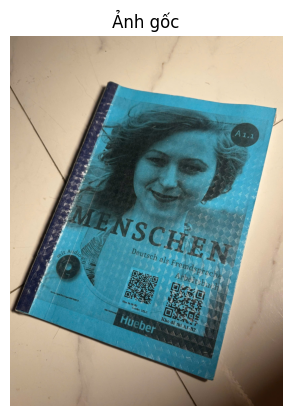

In [4]:
imshow(im, "Ảnh gốc")
plt.show()

## Bước 2. Chuyển sang ảnh xám (Grayscale) — Bài 1

**Vì sao:** tìm biên và tìm contour chỉ cần độ sáng, không cần màu.
Ảnh xám có 1 kênh, chạy nhanh hơn và ít nhiễu hơn ảnh màu 3 kênh.

**Kiểm tra gì:** ảnh hiện ra phải là ảnh xám (đen trắng), `shape` chỉ còn
2 số, ví dụ `(900, 640)`. In `mean` ra xem ảnh sáng hay tối.

shape ảnh xám: (2213, 1630)
độ sáng trung bình: 135.8  (0=tối, 255=sáng)
sáng nhất: 255, tối nhất: 0


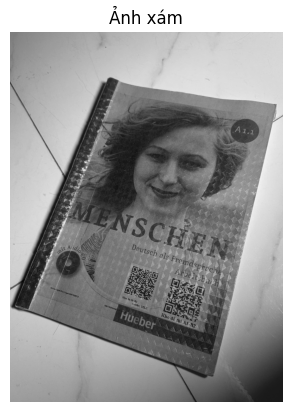

In [5]:
def to_grayscale(image):
    """BGR -> Gray, ảnh 1 kênh."""
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

grayscale = to_grayscale(im)
print(f"shape ảnh xám: {grayscale.shape}")
print(f"độ sáng trung bình: {grayscale.mean():.1f}  (0=tối, 255=sáng)")
print(f"sáng nhất: {grayscale.max()}, tối nhất: {grayscale.min()}")
imshow(grayscale, "Ảnh xám")
plt.show()

## Bước 3. Làm mờ (Blur) — Bài 3

**Vì sao:** Canny rất nhạy với nhiễu. Ảnh chụp bằng điện thoại luôn có
nhiễu hạt, vân chấm trên bìa sách, chữ nhỏ... Nếu không blur trước,
Canny sẽ vẽ biên ở khắp nơi, không chỉ biên tờ giấy.

Dùng **GaussianBlur 3×3**. Kernel lớn hơn (5×5, 7×7) sẽ làm mòn cả
biên tờ giấy, nên đừng vội tăng.

**Kiểm tra gì:** ảnh mờ đi một chút, nhưng chữ và biên tờ giấy vẫn còn rõ.

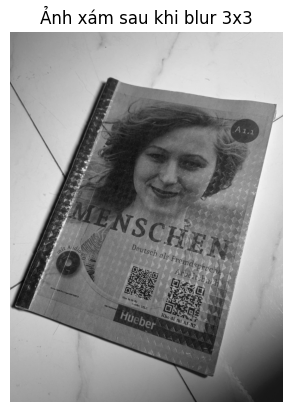

In [6]:
def blur(image):
    """GaussianBlur 3x3 làm mịn nhiễu trước khi tìm biên."""
    return cv2.GaussianBlur(image, (3, 3), 0)

blurred = blur(grayscale)
imshow(blurred, "Ảnh xám sau khi blur 3x3")
plt.show()

## Bước 4. Tìm biên bằng Canny — Bài 4

**Vì sao:** biên là nơi độ sáng thay đổi đột ngột — chính là mép tờ giấy.
Canny 50, 150 nghĩa là: gradient dưới 50 thì bỏ, trên 150 thì giữ chắc,
ở giữa thì giữ nếu nối với biên chắc.

**Kiểm tra gì:**
- In ra `% pixel biên`. Với ảnh giấy trắng trên nền tối, con số này nhỏ
  (khoảng 1–3%), biên tập trung ở mép giấy.
- Nếu % biên lên tới 5–6% và biên rải khắp ảnh (chữ, mặt người, mã QR...),
  thì bước sau sẽ rất khó — đó chính là trường hợp sách MENSCHEN.
  Ghi nhớ con số này, lát nữa đối chiếu với Bước 7.

số pixel biên: 140,075 / 3,607,190 = 3.88%


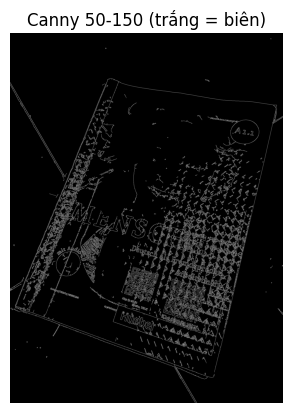

In [7]:
def to_edges(image):
    """Canny 50, 150."""
    return cv2.Canny(image, 50, 150)

edges = to_edges(blurred)
n_edge = int(np.count_nonzero(edges))
print(f"số pixel biên: {n_edge:,} / {edges.size:,} = {100 * n_edge / edges.size:.2f}%")
imshow(edges, "Canny 50-150 (trắng = biên)")
plt.show()

## Bước 5. Xem 5 contour lớn nhất — Bài 6

**Làm gì:** `findContours` trên ảnh biên, sắp xếp theo diện tích giảm dần,
in ra bảng 5 contour lớn nhất.

**Kiểm tra gì — đây là bước chẩn đoán quan trọng nhất:**
- Contour #1 phải là tờ giấy: diện tích lớn (20–90% ảnh), `approx_n = 4`.
- Nếu #1 chỉ có vài trăm px (ví dụ 902 px, 0.5% ảnh) và `approx_n = 12`,
  thì đó **không phải** tờ giấy — đó chỉ là 1 chi tiết nhỏ (huy hiệu, ô QR...).
  Biên tờ giấy đã bị chìm, đừng chạy tiếp, chuyển sang Bước 7.

tìm được 2171 contour
#   diện tích   % ảnh   số đỉnh 
1   7426        0.21    9       
2   3393        0.09    4       
3   2590        0.07    4       
4   1774        0.05    6       
5   1301        0.04    13      


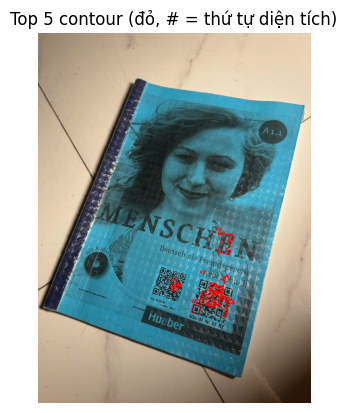

In [8]:
contours, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)
print(f"tìm được {len(contours)} contour")
print(f"{'#':<4}{'diện tích':<12}{'% ảnh':<8}{'số đỉnh':<8}")
for i, cnt in enumerate(contours[:5], 1):
    area = cv2.contourArea(cnt)
    peri = cv2.arcLength(cnt, True)
    approx = cv2.approxPolyDP(cnt, 0.02 * peri, True)
    print(f"{i:<4}{area:<12.0f}{100 * area / edges.size:<8.2f}{len(approx):<8}")

# Vẽ 5 contour lớn nhất lên ảnh gốc để nhìn cho rõ.
anh_5 = im.copy()
for i, cnt in enumerate(contours[:5], 1):
    cv2.drawContours(anh_5, [cnt], -1, (0, 0, 255), 3)
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.putText(anh_5, f"#{i}", (x, max(y - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
imshow(anh_5, "Top 5 contour (đỏ, # = thứ tự diện tích)")
plt.show()

## Bước 6. Tìm 4 góc tờ giấy — Bài 6

**Làm gì:** duyệt 5 contour lớn nhất, contour đầu tiên xấp xỉ được
thành đúng 4 đỉnh (`approxPolyDP`, epsilon = 2% chu vi) thì lấy.
Sau đó sắp xếp 4 góc theo thứ tự: trên-trái, trên-phải, dưới-phải, dưới-trái.

**3 điều kiện bắt buộc (bản gốc thiếu, đã sửa):**
1. Diện tích contour ≥ **10% ảnh** — sách trong ảnh chiếm ~40%, còn ô QR
   hay huy hiệu chỉ ~0.5%.
2. Hộp bao rộng và cao ≥ **25% chiều ảnh**.
3. Hai đỉnh gần nhau nhất cách nhau ≥ **20% cạnh ngắn của ảnh** — chặn
   trường hợp 2 đỉnh trùng nhau.

> ⚠️ **Vì sao phải có 3 điều kiện này?** Bản gốc chấp nhận *bất kỳ*
> contour 4 đỉnh nào, dù nó chỉ là 1 ô QR nhỏ xíu. `warpPerspective`
> sau đó kéo vùng nhỏ đó ra thành 600×850, nên ảnh scan ra là
> **1 màu xanh đặc** (đo được BGR [159, 144, 51], độ lệch chuẩn 0.2).
> Dấu hiệu nhận biết: các chấm `scatter` chụm lại 1 chỗ gần mã QR,
> không nằm ở 4 góc sách.

In [9]:
def reorder(vertices):
    """Sắp xếp 4 góc: trên-trái, trên-phải, dưới-phải, dưới-trái.
    Tổng (x+y) nhỏ nhất là trên-trái, lớn nhất là dưới-phải;
    hiệu (y-x) nhỏ nhất là trên-phải, lớn nhất là dưới-trái."""
    vertices = np.asarray(vertices, dtype=np.float32).reshape(4, 2)
    ordered = np.zeros((4, 2), dtype=np.float32)
    total = vertices.sum(axis=1)  # x + y
    ordered[0] = vertices[np.argmin(total)]  # trên-trái
    ordered[2] = vertices[np.argmax(total)]  # dưới-phải
    diff = np.diff(vertices, axis=1).ravel()  # y - x
    ordered[1] = vertices[np.argmin(diff)]   # trên-phải
    ordered[3] = vertices[np.argmax(diff)]   # dưới-trái
    return ordered


def find_vertices(edges):
    """Tìm 4 góc tờ giấy từ ảnh biên. Không tìm được thì trả về
    4 góc của cả ảnh (coi như không crop) — nhớ là lúc đó ảnh scan
    ra sẽ là nguyên ảnh gốc."""
    height, width = edges.shape[:2]
    image_area = height * width
    cnts, _ = cv2.findContours(edges.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:5]
    for cnt in cnts:
        area = cv2.contourArea(cnt)
        if area < 0.10 * image_area:
            continue  # quá nhỏ: QR, huy hiệu, viên gạch
        approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
        if len(approx) != 4:
            continue
        pts = approx.reshape(4, 2)
        _x, _y, w, h = cv2.boundingRect(pts)
        if w < 0.25 * width or h < 0.25 * height:
            continue  # hộp bao quá hẹp
        min_dist = min(float(np.linalg.norm(pts[i] - pts[j]))
                       for i in range(4) for j in range(i + 1, 4))
        if min_dist < 0.20 * min(width, height):
            continue  # 4 đỉnh chụm lại 1 chỗ
        return reorder(pts)
    return np.array([[0, 0], [width, 0], [width, height], [0, height]], dtype=np.float32)

4 góc tìm được (trên-trái, trên-phải, dưới-phải, dưới-trái):
[[0.0, 0.0], [1630.0, 0.0], [1630.0, 2213.0], [0.0, 2213.0]]
diện tích tứ giác: 3607190 px = 100.0% ảnh


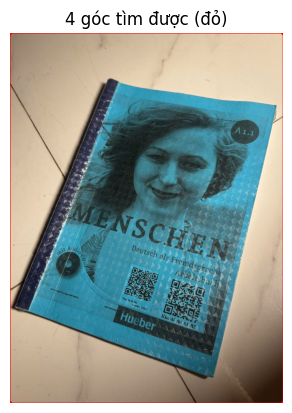

In [10]:
vertices = find_vertices(edges)
print("4 góc tìm được (trên-trái, trên-phải, dưới-phải, dưới-trái):")
print(np.round(vertices, 0).tolist())
# Diện tích tứ giác / diện tích ảnh — phải khoảng 20-90% mới tin được.
quad_area = cv2.contourArea(vertices.astype(np.float32))
print(f"diện tích tứ giác: {quad_area:.0f} px = {100 * quad_area / edges.size:.1f}% ảnh")

anh_dinh = im.copy()
for (x, y) in vertices.astype(int):
    cv2.circle(anh_dinh, (int(x), int(y)), 12, (0, 0, 255), -1)
cv2.polylines(anh_dinh, [vertices.astype(int)], True, (0, 0, 255), 3)
imshow(anh_dinh, "4 góc tìm được (đỏ)")
plt.show()

## Bước 7. Nếu Gray thất bại — tìm bằng màu HSV (dự phòng)

**Khi nào cần bước này?** Khi ở Bước 6, 4 góc tìm được trùng với 4 góc
của cả ảnh (tức là `find_vertices` đã rơi vào fallback), hoặc diện tích
tứ giác < 10% ảnh.

**Vì sao Gray thất bại với sách MENSCHEN?** Đo thật trên ảnh của bạn:

| Điểm | Gray |
|---|---|
| Nền gạch be | 140 |
| Mép trên sách xanh | 149 |
| Giữa sách | 77 |

Sách xanh và nền be nhìn bằng mắt thì khác nhau rõ, nhưng sang Gray
chỉ chênh nhau **9 mức xám** — Canny không thấy biên sách đâu cả.
Còn trong HSV thì sách có Hue **~93 (xanh)**, nền có Hue **~15 (be)**,
tách nhau rất rõ.

**Làm gì:** tách mask theo từng dải Hue bão hòa (đỏ, vàng, xanh lá,
xanh dương), `Closing` lấp lỗ chữ/QR bên trong sách, `Opening` quét
đốm nhiễu, rồi tìm contour 4 đỉnh lớn nhất như Bước 6.

**Lưu ý:** giấy trắng không có màu bão hòa nên bước này sẽ trả về
`None` — đó là đúng, vì giấy trắng thì cách Gray đã làm được rồi.

In [11]:
def find_vertices_by_color(image):
    """Tìm 4 góc bằng MÀU (HSV). Trả về None nếu không tìm được."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    height, width = image.shape[:2]
    image_area = height * width
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    hue_bands = [  # (tên, các dải H) — đỏ cần 2 dải vì H=0 nằm ở 2 đầu thang
        ("do", [(0, 10), (170, 180)]),
        ("vang", [(20, 40)]),
        ("xanh la", [(35, 85)]),
        ("xanh duong", [(85, 115)]),
    ]
    best = None
    for ten, bands in hue_bands:
        mask = np.zeros((height, width), dtype=np.uint8)
        for lo_h, hi_h in bands:
            mask |= cv2.inRange(hsv, np.array((lo_h, 60, 50)), np.array((hi_h, 255, 255)))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in sorted(cnts, key=cv2.contourArea, reverse=True)[:3]:
            area = cv2.contourArea(cnt)
            if not (0.15 * image_area < area < 0.90 * image_area):
                continue
            approx = cv2.approxPolyDP(cnt, 0.02 * cv2.arcLength(cnt, True), True)
            if len(approx) == 4 and (best is None or area > best[0]):
                best = (area, reorder(approx.reshape(4, 2)))
                print(f"  màu {ten}: tìm được tứ giác, diện tích {100 * area / image_area:.1f}% ảnh")
    return best[1] if best else None

Gray + Canny không tìm được tờ giấy, thử bằng màu HSV...
  màu xanh duong: tìm được tứ giác, diện tích 46.3% ảnh
4 góc theo màu: [[638.0, 294.0], [1589.0, 435.0], [1207.0, 2056.0], [82.0, 1652.0]]


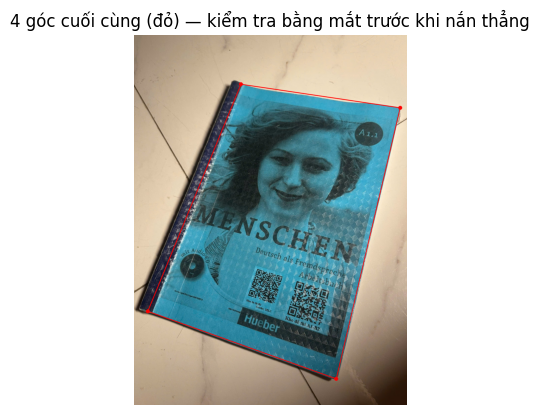

In [12]:
# Chỉ chạy bước này khi Gray đã thất bại (4 góc = 4 góc cả ảnh).
height, width = im.shape[:2]
full_image = np.array([[0, 0], [width, 0], [width, height], [0, height]], dtype=np.float32)
if np.allclose(vertices, full_image):
    print("Gray + Canny không tìm được tờ giấy, thử bằng màu HSV...")
    vertices_mau = find_vertices_by_color(im)
    if vertices_mau is not None:
        vertices = vertices_mau
        print("4 góc theo màu:", np.round(vertices, 0).tolist())
    else:
        print("Cả màu cũng không tìm được — giữ nguyên ảnh gốc, xem Bước 8.")
else:
    print("Gray đã tìm được tờ giấy, không cần bước màu.")
    print("4 góc:", np.round(vertices, 0).tolist())

# Vẽ lại 4 góc cuối cùng để kiểm tra bằng mắt.
anh_cuoi = im.copy()
for (x, y) in vertices.astype(int):
    cv2.circle(anh_cuoi, (int(x), int(y)), 12, (0, 0, 255), -1)
cv2.polylines(anh_cuoi, [vertices.astype(int)], True, (0, 0, 255), 3)
imshow(anh_cuoi, "4 góc cuối cùng (đỏ) — kiểm tra bằng mắt trước khi nắn thẳng")
plt.show()

## Bước 8. Nắn thẳng tờ giấy (Perspective Transform) — Bài 2

**Làm gì:** `getPerspectiveTransform` tính ma trận biến 4 góc tờ giấy
thành hình chữ nhật 600×850, rồi `warpPerspective` áp ma trận đó.

**Kiểm tra gì:** ảnh ra phải là 600×850, tờ giấy thẳng, không còn nghiêng.
Nếu ảnh ra vẫn nghiêng hoặc méo, quay lại Bước 6 kiểm tra thứ tự 4 góc.

ảnh sau khi nắn thẳng: 600x850 (phải là 600x850)


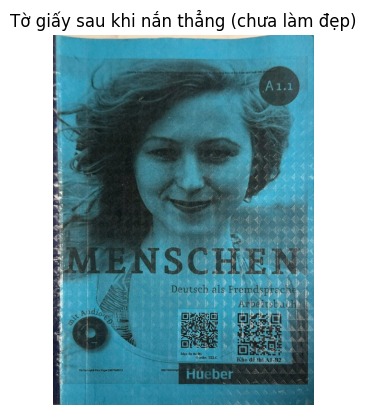

In [13]:
def crop_out(image, vertices, width=600, height=850):
    """Warp perspective: 4 góc tờ giấy -> hình chữ nhật width x height."""
    target = np.array([[0, 0], [width, 0], [width, height], [0, height]], dtype=np.float32)
    transform = cv2.getPerspectiveTransform(np.asarray(vertices, dtype=np.float32), target)
    return cv2.warpPerspective(image, transform, (width, height))

cropped = crop_out(im, vertices)
print(f"ảnh sau khi nắn thẳng: {cropped.shape[1]}x{cropped.shape[0]} (phải là 600x850)")
imshow(cropped, "Tờ giấy sau khi nắn thẳng (chưa làm đẹp)")
plt.show()

## Bước 9. Làm đẹp ảnh scan (Enhancement)

**Làm gì, theo đúng thứ tự trong code:**
1. **Gamma 1.1** — sáng nhẹ toàn ảnh qua bảng tra LUT.
2. **CLAHE trên kênh L của LAB** (clipLimit 2.0, tile 12×12) — tăng tương phản
   cục bộ, chữ rõ hơn mà không cháy sáng.
3. **Tăng saturation** — trộn kênh S gốc với S đã bilateral filter, kẹp về
   [20, 230]. *Lưu ý: tính bằng float rồi mới kẹp, tránh tràn uint8.*
4. **Sharpen** — ảnh gốc × 1.5 − ảnh blur × 0.5.
5. **Bilateral filter cuối** — khử nhiễu mà giữ biên chữ.

**Kiểm tra gì:** so sánh 2 ảnh cạnh nhau — chữ có rõ hơn không?
Nếu ảnh gốc đã nhiễu nhiều, CLAHE + tăng saturation sẽ khuếch đại nhiễu
thành đốm màu trên nền trắng. Khi đó thử giảm `clipLimit` xuống 1.5,
hoặc bỏ bước tăng saturation.

In [14]:
def enhance(image):
    """Làm đẹp ảnh đã nắn thẳng."""
    # 1. Gamma correction
    gamma = 1.1
    table = np.array([((i / 255.0) ** (1.0 / gamma)) * 255 for i in range(256)]).astype("uint8")
    corrected = cv2.LUT(image, table)
    # 2. CLAHE trên kênh L (LAB)
    lab = cv2.cvtColor(corrected, cv2.COLOR_BGR2LAB)
    lightness, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(12, 12))
    lightness = clahe.apply(lightness)
    enhanced = cv2.cvtColor(cv2.merge([lightness, a, b]), cv2.COLOR_LAB2BGR)
    # 3. Tăng saturation
    hsv = cv2.cvtColor(enhanced, cv2.COLOR_BGR2HSV)
    hue, saturation, value = cv2.split(hsv)
    saturation_clean = cv2.bilateralFilter(saturation, 9, 75, 75)
    saturation = np.clip(saturation.astype(np.float32) * 1.2
                         + saturation_clean.astype(np.float32) * 0.3, 20, 230).astype(np.uint8)
    enhanced = cv2.cvtColor(cv2.merge([hue, saturation, value]), cv2.COLOR_HSV2BGR)
    # 4. Sharpen
    blurred = cv2.GaussianBlur(enhanced, (0, 0), 2.0)
    sharpened = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)
    # 5. Khử nhiễu cuối, giữ biên
    return cv2.bilateralFilter(sharpened, 9, 75, 75)

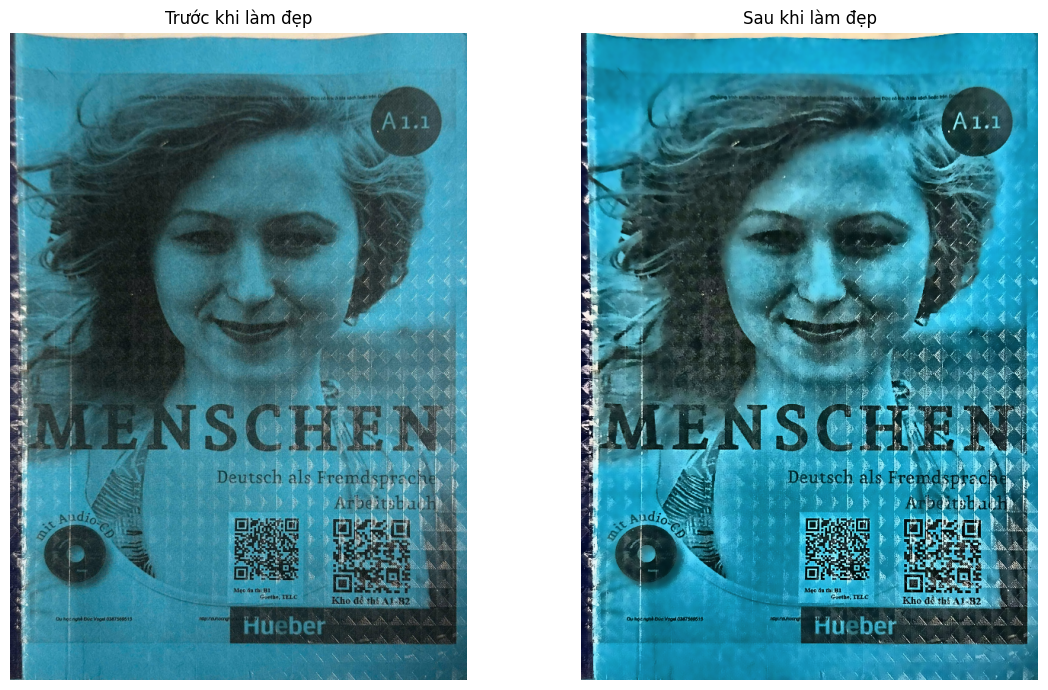

In [15]:
enhanced = enhance(cropped)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
axes[0].imshow(cropped[:, :, ::-1]); axes[0].set_title("Trước khi làm đẹp"); axes[0].axis("off")
axes[1].imshow(enhanced[:, :, ::-1]); axes[1].set_title("Sau khi làm đẹp"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## Bước 10. Ghép tất cả lại thành hàm `scan()`

**Làm gì:** gọi lại đúng các bước 2 → 8 theo thứ tự, thêm 2 kiểm tra:
- Nếu Gray thất bại (4 góc = 4 góc cả ảnh) thì tự chuyển sang HSV.
- In độ lệch chuẩn của ảnh scan: ảnh thật có chữ/hình nên std phải lớn
  (thường > 30). Nếu std < 10 thì ảnh gần như 1 màu đặc — tức là
  4 góc đã lấy nhầm 1 vùng nhỏ rồi kéo giãn ra (lỗi ở Bước 6).

In [16]:
def scan(image, width=600, height=850):
    """Quét 1 ảnh, trả về (ảnh scan, 4 góc tờ giấy)."""
    grayscale = to_grayscale(image)
    edges = to_edges(blur(grayscale))
    verts = find_vertices(edges)
    h, w = image.shape[:2]
    full = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32)
    if np.allclose(verts, full):
        verts_mau = find_vertices_by_color(image)
        if verts_mau is not None:
            print("Gray + Canny không tìm được tờ giấy, dùng HSV theo màu.")
            verts = verts_mau
        else:
            print("Cảnh báo: không tìm được 4 góc, trả về nguyên ảnh gốc.")
    cropped = crop_out(image, verts, width, height)
    return enhance(cropped), verts

  màu xanh duong: tìm được tứ giác, diện tích 46.3% ảnh
Gray + Canny không tìm được tờ giấy, dùng HSV theo màu.
4 góc cuối: [[638.0, 294.0], [1589.0, 435.0], [1207.0, 2056.0], [82.0, 1652.0]]
ảnh scan: 600x850
độ lệch chuẩn ảnh scan: 45.9  (phải > 30; < 10 là gần như 1 màu đặc -> 4 góc sai)


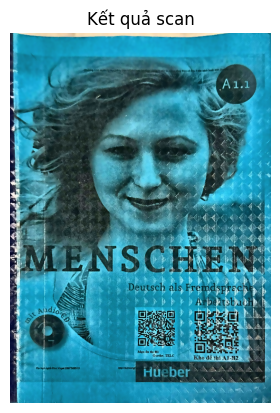

In [17]:
scanned, vertices_cuoi = scan(im)
print(f"4 góc cuối: {np.round(vertices_cuoi, 0).tolist()}")
print(f"ảnh scan: {scanned.shape[1]}x{scanned.shape[0]}")
scan_std = float(cv2.cvtColor(scanned, cv2.COLOR_BGR2GRAY).std())
print(f"độ lệch chuẩn ảnh scan: {scan_std:.1f}  (phải > 30; < 10 là gần như 1 màu đặc -> 4 góc sai)")
imshow(scanned, "Kết quả scan")
plt.show()

## Bước 11. Lưu file và kiểm tra cuối

**Kiểm tra cuối trước khi kết thúc:**
- [ ] File `scanned.jpg` đã được lưu, mở lên đọc được chữ.
- [ ] Ảnh scan là 600×850.
- [ ] Độ lệch chuẩn > 30 (không phải 1 màu đặc).
- [ ] 4 góc ở Bước 6/7 nằm đúng 4 góc sách/giấy khi nhìn bằng mắt.

In [18]:
cv2.imwrite("scanned.jpg", scanned)
print("Đã lưu: scanned.jpg")

# Kiểm tra lại file vừa lưu.
doc_lai = cv2.imread("scanned.jpg")
print(f"đọc lại: shape {doc_lai.shape}, mean gray {cv2.cvtColor(doc_lai, cv2.COLOR_BGR2GRAY).mean():.1f}")
if float(cv2.cvtColor(doc_lai, cv2.COLOR_BGR2GRAY).std()) < 10:
    print("⚠️ Cảnh báo: ảnh scan gần như 1 màu đặc — quay lại Bước 5, 6 kiểm tra lại 4 góc.")
else:
    print("✓ Xong! Ảnh scan có nội dung, không phải 1 màu đặc.")

Đã lưu: scanned.jpg
đọc lại: shape (850, 600, 3), mean gray 104.1
✓ Xong! Ảnh scan có nội dung, không phải 1 màu đặc.


## Tổng kết + bài tập thêm

**Bạn vừa làm xong pipeline:** Gray → Blur → Canny → Contours → 4 góc →
Warp → Enhance → Scan. Đây cũng là pipeline của CamScanner thật.

**Thử thêm để hiểu sâu hơn (mỗi cái chỉ đổi 1 thứ rồi chạy lại từ Bước 4):**
1. Đổi Canny thành (30, 100) hoặc (75, 200) — % pixel biên thay đổi thế nào?
2. Đổi blur thành (5, 5) — biên tờ giấy có mờ đi không?
3. Chụp 1 tờ giấy trắng trên nền tối — Gray có tìm được ngay không, còn cần Bước 7 không?
4. Chụp 1 cuốn sách màu khác (đỏ, xanh lá) — Bước 7 có tìm được không?
5. In ra `vertices` ở Bước 6 cho từng ảnh — góc nào hay sai nhất?